# Ridge vs Lasso vs ElasticNet — a fair comparison
The original notebook compared models with an untuned/coarse alpha grid (Lasso started at alpha=1, which wipes out most coefficients) and a single train/test split.
Here every model is:
- wrapped in a `Pipeline` with `StandardScaler` (no leakage into CV folds),
- tuned over a **log-spaced** alpha grid,
- evaluated with **repeated K-fold CV** (mean ± std), then on the held-out test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## 1. Data

In [2]:
data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
X.corr().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
MedInc,1.00,-0.12,0.33,-0.06,0.00,0.02,-0.08,-0.02
HouseAge,-0.12,1.00,-0.15,-0.08,-0.30,0.01,0.01,-0.11
AveRooms,0.33,-0.15,1.00,0.85,-0.07,-0.00,0.11,-0.03
AveBedrms,-0.06,-0.08,0.85,1.00,-0.07,-0.01,0.07,0.01
Population,0.00,-0.30,-0.07,-0.07,1.00,0.07,-0.11,0.10
AveOccup,0.02,0.01,-0.00,-0.01,0.07,1.00,0.00,0.00
Latitude,-0.08,0.01,0.11,0.07,-0.11,0.00,1.00,-0.92
Longitude,-0.02,-0.11,-0.03,0.01,0.10,0.00,-0.92,1.00


Note the strong correlation between `AveRooms` and `AveBedrms`, and between `Latitude` and `Longitude`. That's the situation where Ridge and Lasso behave differently.

## 2. Tune each model

In [3]:
alphas = np.logspace(-4, 2, 30)
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

models = {
    'Linear':     (make_pipeline(StandardScaler(), LinearRegression()), {}),
    'Ridge':      (make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': alphas}),
    'Lasso':      (make_pipeline(StandardScaler(), Lasso(max_iter=10000)), {'lasso__alpha': alphas}),
    'ElasticNet': (make_pipeline(StandardScaler(), ElasticNet(max_iter=10000)),
                   {'elasticnet__alpha': alphas, 'elasticnet__l1_ratio': [0.1, 0.5, 0.9]}),
}

best = {}
for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, scoring='neg_mean_squared_error', cv=5)
    gs.fit(X_train, y_train)
    best[name] = gs.best_estimator_
    print(f'{name:<11} best params: {gs.best_params_}')

Linear      best params: {}


Ridge       best params: {'ridge__alpha': np.float64(0.0001)}


Lasso       best params: {'lasso__alpha': np.float64(0.001082636733874054)}


ElasticNet  best params: {'elasticnet__alpha': np.float64(0.001082636733874054), 'elasticnet__l1_ratio': 0.9}


## 3. Cross-validated comparison (mean ± std)

In [4]:
rows = []
for name, est in best.items():
    s = cross_validate(est, X_train, y_train, cv=cv,
                       scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'})
    rows.append({'model': name,
                 'CV R2 mean': s['test_r2'].mean(), 'CV R2 std': s['test_r2'].std(),
                 'CV RMSE mean': -s['test_rmse'].mean(), 'CV RMSE std': s['test_rmse'].std()})
cv_results = pd.DataFrame(rows).set_index('model').round(4)
cv_results

,CV R2 mean,CV R2 std,CV RMSE mean,CV RMSE std
model,,,,
Linear,0.6075,0.0139,0.7248,0.0119
Ridge,0.6075,0.0139,0.7248,0.0119
Lasso,0.6075,0.0139,0.7248,0.0120
ElasticNet,0.6075,0.0139,0.7248,0.0120


If the gaps between models are smaller than the std, the models are effectively **tied**.

## 4. Held-out test set

In [5]:
test_rows = []
for name, est in best.items():
    p = est.predict(X_test)
    test_rows.append({'model': name,
                      'R2': r2_score(y_test, p),
                      'RMSE': mean_squared_error(y_test, p) ** 0.5,
                      'MAE': mean_absolute_error(y_test, p)})
pd.DataFrame(test_rows).set_index('model').round(4)

,R2,RMSE,MAE
model,,,
Linear,0.5958,0.7284,0.5272
Ridge,0.5958,0.7284,0.5272
Lasso,0.5964,0.7278,0.5273
ElasticNet,0.5964,0.7278,0.5273


## 5. Coefficients — what each penalty actually does

Zeroed-out features: {'Linear': 0, 'Ridge': 0, 'Lasso': 1, 'ElasticNet': 1}


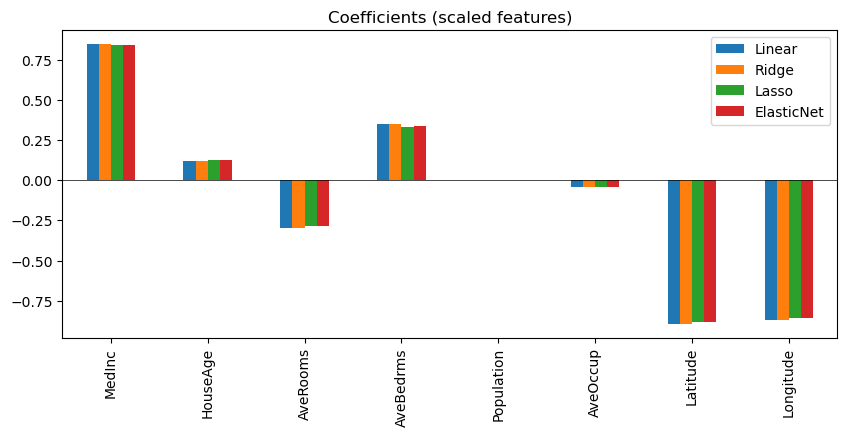

,Linear,Ridge,Lasso,ElasticNet
MedInc,0.8492,0.8492,0.8435,0.8439
HouseAge,0.1221,0.1221,0.1228,0.1229
AveRooms,-0.2996,-0.2996,-0.2847,-0.2858
AveBedrms,0.3484,0.3484,0.3334,0.3345
Population,-0.0009,-0.0009,-0.0000,-0.0000
AveOccup,-0.0417,-0.0417,-0.0406,-0.0407
Latitude,-0.8939,-0.8939,-0.8822,-0.8820
Longitude,-0.8686,-0.8686,-0.8562,-0.8561


In [6]:
coefs = pd.DataFrame({name: est[-1].coef_ for name, est in best.items()}, index=X.columns)
print('Zeroed-out features:', {n: int((coefs[n] == 0).sum()) for n in coefs})
coefs.plot.bar(figsize=(10, 4)); plt.axhline(0, color='k', lw=0.5); plt.title('Coefficients (scaled features)'); plt.show()
coefs.round(4)

## 6. Regularization paths — score vs alpha

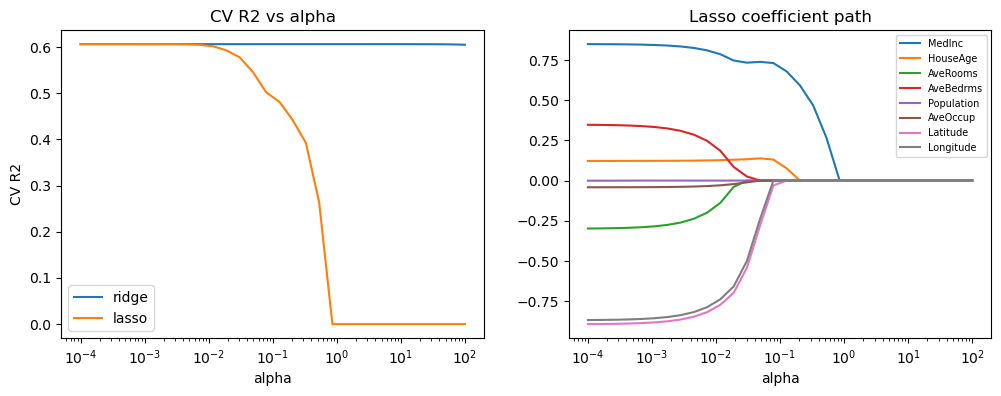

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for Model, key in [(Ridge, 'ridge'), (Lasso, 'lasso')]:
    gs = GridSearchCV(make_pipeline(StandardScaler(), Model(max_iter=10000) if Model is Lasso else Model()),
                      {f'{key}__alpha': alphas}, scoring='r2', cv=5).fit(X_train, y_train)
    ax[0].semilogx(alphas, gs.cv_results_['mean_test_score'], label=key)
    path = [Model(alpha=a, max_iter=10000).fit(StandardScaler().fit_transform(X_train), y_train).coef_ for a in alphas]         if Model is Lasso else None
ax[0].set(xlabel='alpha', ylabel='CV R2', title='CV R2 vs alpha'); ax[0].legend()
ax[1].semilogx(alphas, path); ax[1].set(xlabel='alpha', title='Lasso coefficient path'); ax[1].legend(X.columns, fontsize=7)
plt.show()

Notice the **original grid** (alpha from 1 to 90) is far to the right of these curves. For Lasso, R2 has collapsed there. Ridge barely changes because L2 on 8 scaled features with ~14k rows is a tiny penalty.

## 7. Where Ridge wins: correlated features, many small effects
California housing has only 8 features and lots of data, so regularization barely matters and all models tie. Below is a synthetic setting with 100 features, few samples, and every feature carrying a small amount of real signal.

In [8]:
from sklearn.datasets import make_regression
def compare(X, y, title):
    out = {}
    for name, (pipe, grid) in models.items():
        if name == 'Linear': continue
        gs = GridSearchCV(pipe, grid, scoring='r2', cv=5).fit(X, y)
        out[name] = cross_validate(gs.best_estimator_, X, y, cv=cv, scoring='r2')['test_score'].mean()
    print(title, {k: round(v, 3) for k, v in out.items()})

# dense signal: all 100 features informative, correlated (low effective rank)
Xd, yd = make_regression(n_samples=150, n_features=100, n_informative=100,
                         effective_rank=10, noise=5, random_state=0)
compare(Xd, yd, 'Dense / correlated  ->')

# sparse signal: only 5 of 100 features matter
Xs, ys = make_regression(n_samples=150, n_features=100, n_informative=5, noise=5, random_state=0)
compare(Xs, ys, 'Sparse signal       ->')

Dense / correlated  -> {'Ridge': np.float64(0.691), 'Lasso': np.float64(0.614), 'ElasticNet': np.float64(0.678)}


Sparse signal       -> {'Ridge': np.float64(0.979), 'Lasso': np.float64(0.997), 'ElasticNet': np.float64(0.991)}


## 8. Takeaways
| Situation | Usually best |
|---|---|
| Few features, lots of data (this dataset) | All tie, regularization ≈ irrelevant |
| Many features, only a few matter | **Lasso** (feature selection) |
| Many correlated features, all contribute a bit | **Ridge** |
| Not sure / groups of correlated useful features | **ElasticNet** |

So Lasso "winning" on the original notebook was an artifact of the alpha grid and a single split, not proof that Ridge is useless.